# Caso 04 — VueltaFit, gimnasios: ¿qué plan deja más dinero?
## Día 5 (viernes) — Que se entienda y cambie algo (Visualizaciones Ejecutivas y One-Pager para Marta)

En el cierre de la semana consolidamos en **SQL (DuckDB) + Python (Pandas y Seaborn)** toda la cadena de evidencia construida de lunes a jueves para entrar a la reunión del Comité de Dirección con **Marta Belmonte (CEO)**, **Rubén Ortega (Head de Growth)**, **Nuria Vega (Lead de Datos)** y **Álex Cordero (Operaciones y Sistemas)**.

Cada bloque imprime sus cifras exactas y genera en `reports/` los **4 gráficos ejecutivos con nomenclatura estándar** (además de mantener `reports/figures/` por compatibilidad):
1. **`01_ltv_inicial_vs_tasa_renovacion.png` — El espejismo del prepago:** Primero le damos la razón a Rubén en el cobro inicial (**LTV medio de $466,25\text{ €}$ en anual vs $300,90\text{ €}$ en mensual**, $+55,0\%$) y al lado mostramos la grieta real al vencimiento (**Tasa de Renovación del $41,1\%$ en anual vs $59,6\%$ en mensual**, $-18,5\text{ pp}$).
2. **`02_cementerio_inactivos_sesgo_supervivencia.png` — El cementerio de socios inactivos (Sesgo de Supervivencia):** El **$35,5\%$ de los socios anuales con cuota activa (`980` de `2.759`)** llevan más de un mes sin pisar el gimnasio, frente a solo el **$12,7\%$ en mensuales (`205` de `1.611`)**. El $82,7\%$ de los socios «fantasma» están ocultos bajo el prepago anual.
3. **`03_escalera_habito_21_dias.png` — La palanca real (Escalera del Hábito en 21 días y Clases Colectivas):** La tasa de renovación salta del **$22,1\%$ (`0–2` visitas)** al **$50,9\%$ (`3–5` visitas)** y hasta el **$78,6\%$ (`≥ 6` visitas)** en los primeros 21 días, mientras que **reservar al menos una clase colectiva en los primeros 14 días duplica la renovación ($73,3\%$ vs $36,8\%$)**.
4. **`04_control_confusion_habito_vs_plan.png` — El blindaje (Control de Confusión Hábito vs. Plan):** Dentro del mismo tramo de asistencia temprana, **anual y mensual renuevan exactamente igual** ($78,2\%$ vs $78,8\%$ en alta asistencia; $22,6\%$ vs $21,1\%$ en baja asistencia). El anual se hunde en el agregado porque el **$51,6\%$ de sus socios cae en baja asistencia inicial** (frente a solo el $18,9\%$ de los mensuales).

In [1]:
%matplotlib inline
import os
from pathlib import Path
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

REPORTS_DIR = Path("reports")
FIGURES_DIR = REPORTS_DIR / "figures"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

con = duckdb.connect()
DATA_CLEAN = Path("data/clean")
for t in ["socios", "suscripciones", "checkins", "clases", "reservas", "pagos", "sedes"]:
    csv_path = (DATA_CLEAN / f"{t}_clean.csv").as_posix()
    con.execute(f"CREATE OR REPLACE VIEW v_{t} AS SELECT * FROM read_csv_auto('{csv_path}')")

# 1. Dataset base de los 3.757 contratos vencidos con asistencia temprana (21d) y reserva de clase (14d)
q_base = '''
WITH vencidas AS (
    SELECT *
    FROM v_suscripciones
    WHERE TRY_CAST(fecha_fin AS DATE) <= DATE '2024-06-30'
),
con_renov AS (
    SELECT 
        v.*,
        EXISTS (
            SELECT 1 
            FROM v_suscripciones s2 
            WHERE s2.socio_id = v.socio_id 
              AND s2.suscripcion_id != v.suscripcion_id
              AND TRY_CAST(s2.fecha_inicio AS DATE) >= TRY_CAST(v.fecha_fin AS DATE)
              AND TRY_CAST(s2.fecha_inicio AS DATE) <= TRY_CAST(v.fecha_fin AS DATE) + INTERVAL 30 DAY
        ) AS renovo
    FROM vencidas v
),
checkins_21d AS (
    SELECT 
        cr.suscripcion_id,
        COUNT(c.checkin_id) AS n_checkins_21d
    FROM con_renov cr
    LEFT JOIN v_checkins c 
        ON cr.socio_id = c.socio_id
       AND TRY_CAST(c.fecha_hora AS DATE) >= TRY_CAST(cr.fecha_inicio AS DATE)
       AND TRY_CAST(c.fecha_hora AS DATE) <= TRY_CAST(cr.fecha_inicio AS DATE) + INTERVAL 21 DAY
    GROUP BY cr.suscripcion_id
),
res_14d AS (
    SELECT 
        cr.suscripcion_id,
        COUNT(r.reserva_id) AS n_reservas_14d
    FROM con_renov cr
    LEFT JOIN v_reservas r
        ON cr.socio_id = r.socio_id
       AND TRY_CAST(r.fecha_reserva AS DATE) >= TRY_CAST(cr.fecha_inicio AS DATE)
       AND TRY_CAST(r.fecha_reserva AS DATE) <= TRY_CAST(cr.fecha_inicio AS DATE) + INTERVAL 14 DAY
    GROUP BY cr.suscripcion_id
)
SELECT 
    cr.suscripcion_id,
    cr.socio_id,
    cr.tipo_plan,
    cr.renovo,
    COALESCE(ch.n_checkins_21d, 0) AS checkins_21d,
    CASE 
        WHEN COALESCE(ch.n_checkins_21d, 0) <= 2 THEN 'Baja (0-2)'
        WHEN COALESCE(ch.n_checkins_21d, 0) <= 5 THEN 'Media (3-5)'
        ELSE 'Alta (6+)'
    END AS tramo_asistencia,
    COALESCE(r.n_reservas_14d, 0) > 0 AS reservo_clase_14d
FROM con_renov cr
JOIN checkins_21d ch USING (suscripcion_id)
JOIN res_14d r USING (suscripcion_id);
'''
df_base = con.execute(q_base).df()

# 2. Tabla Maestra por Plan (Socios, LTV, Contratos Vencidos, Renovación, Activos e Inactivos >28-30d)
q_maestra_plan = '''
WITH primer_plan AS (
    SELECT socio_id, tipo_plan
    FROM (
        SELECT socio_id, tipo_plan, ROW_NUMBER() OVER (PARTITION BY socio_id ORDER BY fecha_inicio) AS rn
        FROM v_suscripciones
    ) WHERE rn = 1
),
pagos_socio AS (
    SELECT socio_id, SUM(importe) AS total_pagado
    FROM v_pagos
    WHERE es_pago_valido
    GROUP BY socio_id
),
ltv_plan AS (
    SELECT 
        p.tipo_plan,
        COUNT(p.socio_id) AS socios_totales,
        ROUND(COUNT(p.socio_id) * 100.0 / (SELECT COUNT(*) FROM primer_plan), 2) AS cuota_socios_pct,
        ROUND(SUM(COALESCE(ps.total_pagado, 0)), 2) AS ingresos_totales_eur,
        ROUND(AVG(COALESCE(ps.total_pagado, 0)), 2) AS ltv_medio_eur
    FROM primer_plan p
    LEFT JOIN pagos_socio ps USING (socio_id)
    GROUP BY p.tipo_plan
),
activos_plan AS (
    SELECT DISTINCT socio_id, tipo_plan
    FROM v_suscripciones
    WHERE activa
),
vienen_4sem AS (
    SELECT DISTINCT socio_id
    FROM v_checkins
    WHERE TRY_CAST(fecha_hora AS DATE) >= DATE '2024-06-30' - INTERVAL 28 DAY
      AND TRY_CAST(fecha_hora AS DATE) <= DATE '2024-06-30'
),
hueco_plan AS (
    SELECT 
        ap.tipo_plan,
        COUNT(ap.socio_id) AS activos_pagando,
        COUNT(v.socio_id) AS activos_asisten,
        COUNT(ap.socio_id) - COUNT(v.socio_id) AS inactivos_fantasmas,
        ROUND((COUNT(ap.socio_id) - COUNT(v.socio_id)) * 100.0 / COUNT(ap.socio_id), 2) AS pct_inactivos_plan
    FROM activos_plan ap
    LEFT JOIN vienen_4sem v ON ap.socio_id = v.socio_id
    GROUP BY ap.tipo_plan
),
renov_plan AS (
    SELECT
        tipo_plan,
        COUNT(*) AS contratos_vencidos,
        SUM(CASE WHEN renovo THEN 1 ELSE 0 END) AS contratos_renovados,
        ROUND(AVG(CASE WHEN renovo THEN 1.0 ELSE 0.0 END) * 100, 2) AS tasa_renovacion_pct,
        ROUND((1.0 - AVG(CASE WHEN renovo THEN 1.0 ELSE 0.0 END)) * 100, 2) AS tasa_churn_pct,
        ROUND(AVG(checkins_21d), 2) AS visitas_medias_21d,
        ROUND(AVG(CASE WHEN tramo_asistencia = 'Baja (0-2)' THEN 1.0 ELSE 0.0 END) * 100, 1) AS pct_baja_21d,
        ROUND(AVG(CASE WHEN tramo_asistencia = 'Media (3-5)' THEN 1.0 ELSE 0.0 END) * 100, 1) AS pct_media_21d,
        ROUND(AVG(CASE WHEN tramo_asistencia = 'Alta (6+)' THEN 1.0 ELSE 0.0 END) * 100, 1) AS pct_alta_21d,
        ROUND(AVG(CASE WHEN reservo_clase_14d THEN 1.0 ELSE 0.0 END) * 100, 1) AS pct_reservo_14d
    FROM df_base
    GROUP BY tipo_plan
)
SELECT 
    l.tipo_plan,
    l.socios_totales,
    l.cuota_socios_pct,
    l.ingresos_totales_eur,
    l.ltv_medio_eur,
    r.contratos_vencidos,
    r.contratos_renovados,
    r.tasa_renovacion_pct,
    r.tasa_churn_pct,
    h.activos_pagando,
    h.inactivos_fantasmas,
    h.pct_inactivos_plan,
    r.visitas_medias_21d,
    r.pct_baja_21d,
    r.pct_media_21d,
    r.pct_alta_21d,
    r.pct_reservo_14d
FROM ltv_plan l
JOIN renov_plan r USING (tipo_plan)
JOIN hueco_plan h USING (tipo_plan)
ORDER BY l.ltv_medio_eur DESC;
'''
df_maestra_plan = con.execute(q_maestra_plan).df()
print("=== TABLA MAESTRA POR TIPO DE PLAN (9.000 SOCIOS | 3.757 VENCIDOS | 4.370 ACTIVOS) ===")
display(df_maestra_plan)


=== TABLA MAESTRA POR TIPO DE PLAN (9.000 SOCIOS | 3.757 VENCIDOS | 4.370 ACTIVOS) ===


,tipo_plan,socios_totales,cuota_socios_pct,ingresos_totales_eur,ltv_medio_eur,contratos_vencidos,contratos_renovados,tasa_renovacion_pct,tasa_churn_pct,activos_pagando,inactivos_fantasmas,pct_inactivos_plan,visitas_medias_21d,pct_baja_21d,pct_media_21d,pct_alta_21d,pct_reservo_14d
0,anual,3660,40.67,1706484.0,466.25,1530,629.0,41.11,58.89,2759,980,35.52,3.41,51.6,28.4,20.1,25.4
1,mensual,5340,59.33,1606794.9,300.90,2227,1328.0,59.63,40.37,1611,205,12.73,6.06,18.9,30.9,50.1,53.2


### Análisis de la Tabla Maestra por Plan y Presentación del Gráfico 1
La tabla maestra resume la paradoja completa de VueltaFit:
* **En la superficie (lo que mira Growth):** El plan `anual` (`3.660` socios, $40,67\%$) registra un **LTV medio cobrado de $466,25\text{ €}$** frente a los **$300,90\text{ €}$** del `mensual` (`5.340` socios, $59,33\%$).
* **Al vencimiento (lo que decide el negocio a medio plazo):** La tasa de renovación del `anual` se hunde al **$41,11\%$** ($58,89\%$ de *churn*), frente al **$59,63\%$** del `mensual` ($40,37\%$ de *churn*).

A continuación construimos el **Gráfico 1 (`01_ltv_inicial_vs_tasa_renovacion.png`)** siguiendo la regla narrativa de Marta: **primero darle la razón a Rubén en el LTV inicial, y justo al lado mostrar la caída de 18,5 puntos en renovación**.

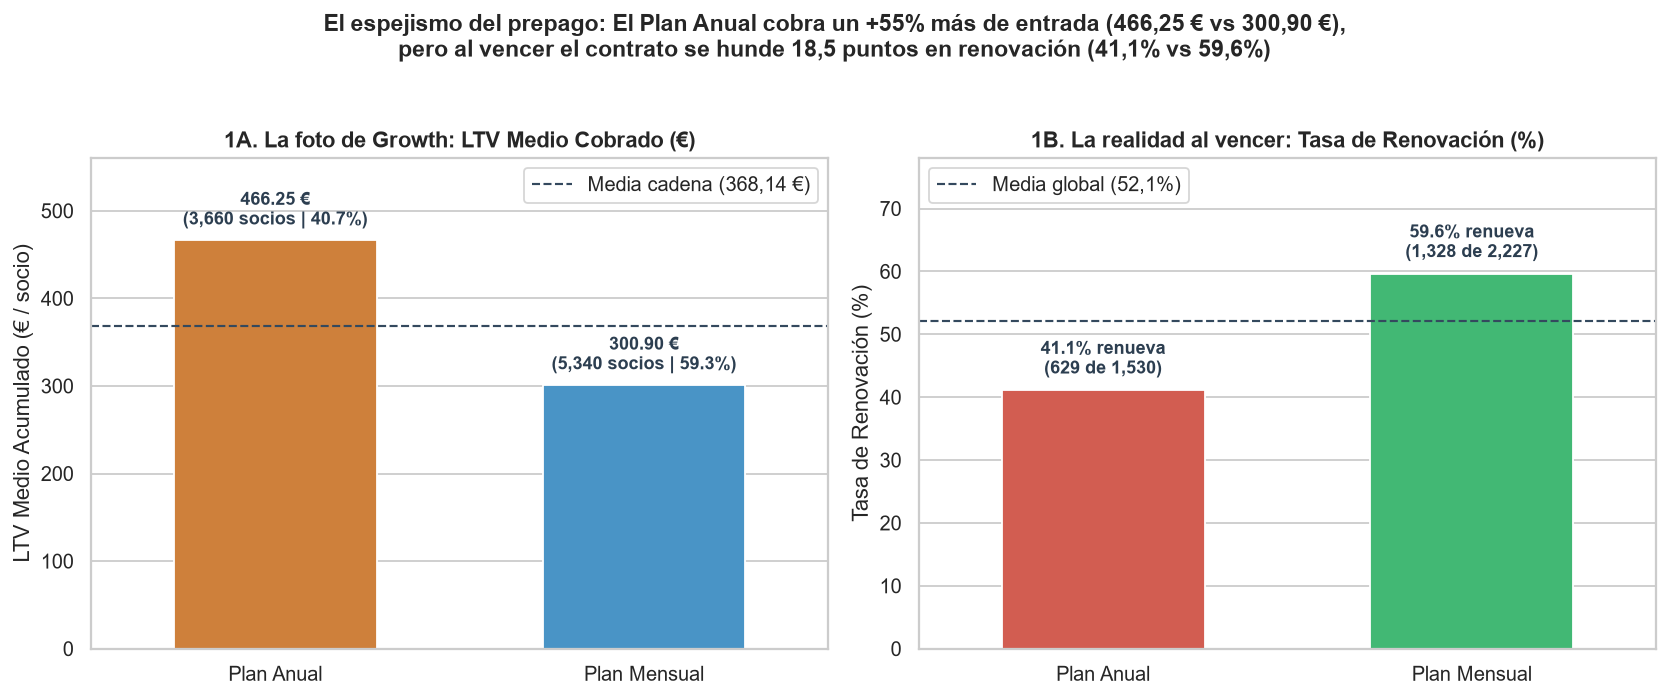

=== CIFRAS DEL GRÁFICO 1: LTV INICIAL vs TASA DE RENOVACIÓN ===
- anual  : 3,660 socios (40.67%) | LTV medio: 466.25 € | Renovación: 41.11% (629/1530) | Churn: 58.89%
- mensual: 5,340 socios (59.33%) | LTV medio: 300.90 € | Renovación: 59.63% (1328/2227) | Churn: 40.37%


In [2]:
# --- GRÁFICO 1: El espejismo del prepago (LTV Inicial vs Tasa de Renovación) ---
sns.set_theme(style="whitegrid", font="sans-serif")
plt.rcParams["figure.dpi"] = 130

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
orden_planes = ["anual", "mensual"]
etiquetas_planes = ["Plan Anual", "Plan Mensual"]
colores_g1_left = ["#E67E22", "#3498DB"]
colores_g1_right = ["#E74C3C", "#2ECC71"]

# Panel 1A: LTV Medio Inicial
df_g1 = df_maestra_plan.set_index("tipo_plan").loc[orden_planes].reset_index()
df_g1["etiqueta"] = etiquetas_planes

bars1 = sns.barplot(
    data=df_g1, x="etiqueta", y="ltv_medio_eur", hue="etiqueta",
    palette=colores_g1_left, legend=False, width=0.55, ax=axes[0]
)
axes[0].axhline(368.14, color="#34495E", linestyle="--", linewidth=1.2, label="Media cadena (368,14 €)")
axes[0].set_title("1A. La foto de Growth: LTV Medio Cobrado (€)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("")
axes[0].set_ylabel("LTV Medio Acumulado (€ / socio)")
axes[0].set_ylim(0, 560)
axes[0].legend(loc="upper right", frameon=True)
for i, r in enumerate(df_g1.itertuples()):
    axes[0].text(
        i, r.ltv_medio_eur + 12,
        f"{r.ltv_medio_eur:.2f} €\n({r.socios_totales:,} socios | {r.cuota_socios_pct:.1f}%)",
        ha="center", va="bottom", fontweight="bold", fontsize=10, color="#2C3E50"
    )

# Panel 1B: Tasa de Renovación al Vencimiento
bars2 = sns.barplot(
    data=df_g1, x="etiqueta", y="tasa_renovacion_pct", hue="etiqueta",
    palette=colores_g1_right, legend=False, width=0.55, ax=axes[1]
)
axes[1].axhline(52.09, color="#34495E", linestyle="--", linewidth=1.2, label="Media global (52,1%)")
axes[1].set_title("1B. La realidad al vencer: Tasa de Renovación (%)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("")
axes[1].set_ylabel("Tasa de Renovación (%)")
axes[1].set_ylim(0, 78)
axes[1].legend(loc="upper left", frameon=True)
for i, r in enumerate(df_g1.itertuples()):
    axes[1].text(
        i, r.tasa_renovacion_pct + 1.8,
        f"{r.tasa_renovacion_pct:.1f}% renueva\n({int(r.contratos_renovados):,} de {int(r.contratos_vencidos):,})",
        ha="center", va="bottom", fontweight="bold", fontsize=10, color="#2C3E50"
    )

plt.suptitle(
    "El espejismo del prepago: El Plan Anual cobra un +55% más de entrada (466,25 € vs 300,90 €),\npero al vencer el contrato se hunde 18,5 puntos en renovación (41,1% vs 59,6%)",
    fontsize=13, fontweight="bold", y=1.03
)
plt.tight_layout()
out_g1 = REPORTS_DIR / "01_ltv_inicial_vs_tasa_renovacion.png"
plt.savefig(out_g1, dpi=300, bbox_inches="tight")
plt.show()

print("=== CIFRAS DEL GRÁFICO 1: LTV INICIAL vs TASA DE RENOVACIÓN ===")
for r in df_g1.itertuples():
    print(f"- {r.tipo_plan:7s}: {r.socios_totales:,} socios ({r.cuota_socios_pct:.2f}%) | LTV medio: {r.ltv_medio_eur:.2f} € | Renovación: {r.tasa_renovacion_pct:.2f}% ({int(r.contratos_renovados)}/{int(r.contratos_vencidos)}) | Churn: {r.tasa_churn_pct:.2f}%")


### Análisis del Gráfico 1 y Presentación del Gráfico 2 (`02_cementerio_inactivos_sesgo_supervivencia.png`)
* **Lectura del Gráfico 1:** La ventaja de $466,25\text{ €}$ frente a $300,90\text{ €}$ no proviene de que el socio anual se quede más años, sino de que **adelanta 12 meses de caja el día del alta**. Cuando llega la hora de renovar, el anual cae al **$41,1\%$** mientras el mensual alcanza el **$59,6\%$** ($+18,5\text{ pp}$).
* **Por qué nadie veía el problema durante el año (Gráfico 2):** En el plan mensual, el socio que pierde el hábito se da de baja en seguida; en el anual, como ya pagó, sigue figurando como «socio activo» aunque haya abandonado el gimnasio meses atrás. A continuación visualizamos este **cementerio de socios inactivos (sesgo de supervivencia)**.

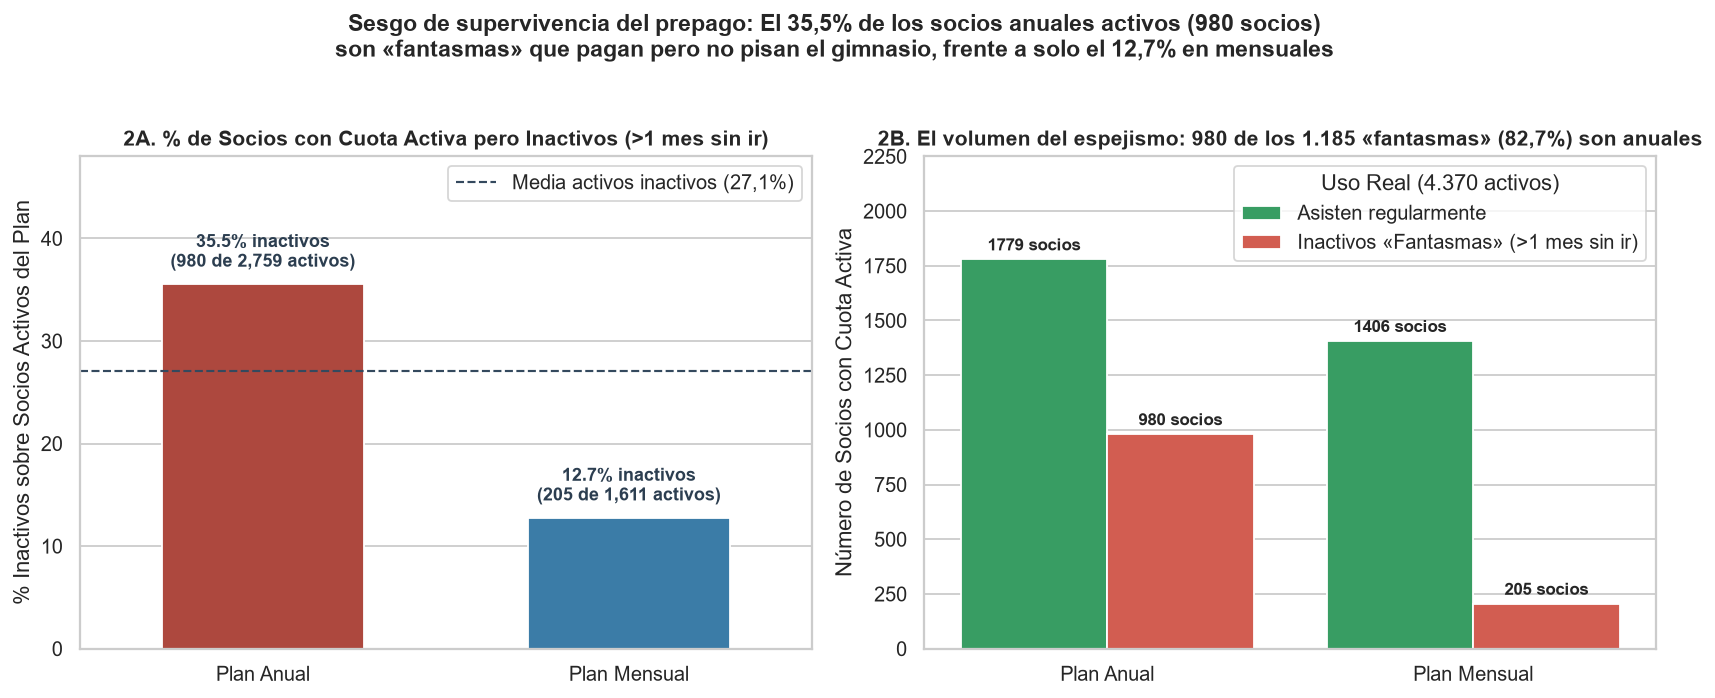

=== CIFRAS DEL GRÁFICO 2: CEMENTERIO DE INACTIVOS (SESGO DE SUPERVIVENCIA) ===
- Total socios pagando cuota activa: 4,370 | Asisten: 3,185 (72.88%) | Inactivos >1 mes: 1,185 (27.12%)
- anual  : 2,759 activos | 980 inactivos (35.52% del plan | 82.7% de todos los fantasmas)
- mensual: 1,611 activos | 205 inactivos (12.73% del plan | 17.3% de todos los fantasmas)


In [3]:
# --- GRÁFICO 2: El cementerio de socios inactivos y el sesgo de supervivencia ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

# Panel 2A: % de socios activos pagando pero inactivos (>28-30 días sin check-in)
bars_2a = sns.barplot(
    data=df_g1, x="etiqueta", y="pct_inactivos_plan", hue="etiqueta",
    palette=["#C0392B", "#2980B9"], legend=False, width=0.55, ax=axes[0]
)
axes[0].axhline(27.12, color="#34495E", linestyle="--", linewidth=1.2, label="Media activos inactivos (27,1%)")
axes[0].set_title("2A. % de Socios con Cuota Activa pero Inactivos (>1 mes sin ir)", fontsize=11.5, fontweight="bold")
axes[0].set_xlabel("")
axes[0].set_ylabel("% Inactivos sobre Socios Activos del Plan")
axes[0].set_ylim(0, 48)
axes[0].legend(loc="upper right", frameon=True)
for i, r in enumerate(df_g1.itertuples()):
    axes[0].text(
        i, r.pct_inactivos_plan + 1.2,
        f"{r.pct_inactivos_plan:.1f}% inactivos\n({int(r.inactivos_fantasmas):,} de {int(r.activos_pagando):,} activos)",
        ha="center", va="bottom", fontweight="bold", fontsize=10, color="#2C3E50"
    )

# Panel 2B: Desglose en volumen de los 4.370 socios activos (Asisten vs Fantasmas)
df_g2_vol = pd.DataFrame({
    "etiqueta": ["Plan Anual", "Plan Mensual"],
    "Asisten regularmente": [2759 - 980, 1611 - 205],
    "Inactivos «Fantasmas» (>1 mes sin ir)": [980, 205]
}).melt(id_vars="etiqueta", var_name="estado_asistencia", value_name="socios")

sns.barplot(
    data=df_g2_vol, x="etiqueta", y="socios", hue="estado_asistencia",
    palette=["#27AE60", "#E74C3C"], ax=axes[1]
)
axes[1].set_title("2B. El volumen del espejismo: 980 de los 1.185 «fantasmas» (82,7%) son anuales", fontsize=11.5, fontweight="bold")
axes[1].set_xlabel("")
axes[1].set_ylabel("Número de Socios con Cuota Activa")
axes[1].set_ylim(0, 2250)
axes[1].legend(title="Uso Real (4.370 activos)", loc="upper right", frameon=True)
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%d socios", padding=3, fontweight="bold", fontsize=9.5)

plt.suptitle(
    "Sesgo de supervivencia del prepago: El 35,5% de los socios anuales activos (980 socios)\nson «fantasmas» que pagan pero no pisan el gimnasio, frente a solo el 12,7% en mensuales",
    fontsize=13, fontweight="bold", y=1.03
)
plt.tight_layout()
out_g2 = REPORTS_DIR / "02_cementerio_inactivos_sesgo_supervivencia.png"
plt.savefig(out_g2, dpi=300, bbox_inches="tight")
plt.show()

print("=== CIFRAS DEL GRÁFICO 2: CEMENTERIO DE INACTIVOS (SESGO DE SUPERVIVENCIA) ===")
print(f"- Total socios pagando cuota activa: 4,370 | Asisten: 3,185 (72.88%) | Inactivos >1 mes: 1,185 (27.12%)")
for r in df_g1.itertuples():
    cuota_fantasmas = r.inactivos_fantasmas / 1185.0 * 100
    print(f"- {r.tipo_plan:7s}: {int(r.activos_pagando):,} activos | {int(r.inactivos_fantasmas):,} inactivos ({r.pct_inactivos_plan:.2f}% del plan | {cuota_fantasmas:.1f}% de todos los fantasmas)")


### Análisis del Gráfico 2 y Presentación del Gráfico 3 (`03_escalera_habito_21_dias.png`)
* **Lectura del Gráfico 2:** El prepago anual funciona como una anestesia contable: **`980` socios anuales ($35,5\%$ de los activos del plan)** ya han abandonado el gimnasio en silencio pero no aparecen como baja hasta el día en que vence su año.
* **La palanca conductual (Gráfico 3):** Una vez descartados la edad ($34,8$ vs $34,6$ años), el canal de captación ($49,2\%\text{--}55,0\%$) y la ciudad ($49,7\%\text{--}54,3\%$), medimos la verdadera causa de la retención: **cuántas veces pisa el socio el club en sus primeros 21 días** y si **reserva al menos una clase colectiva en sus primeros 14 días**.

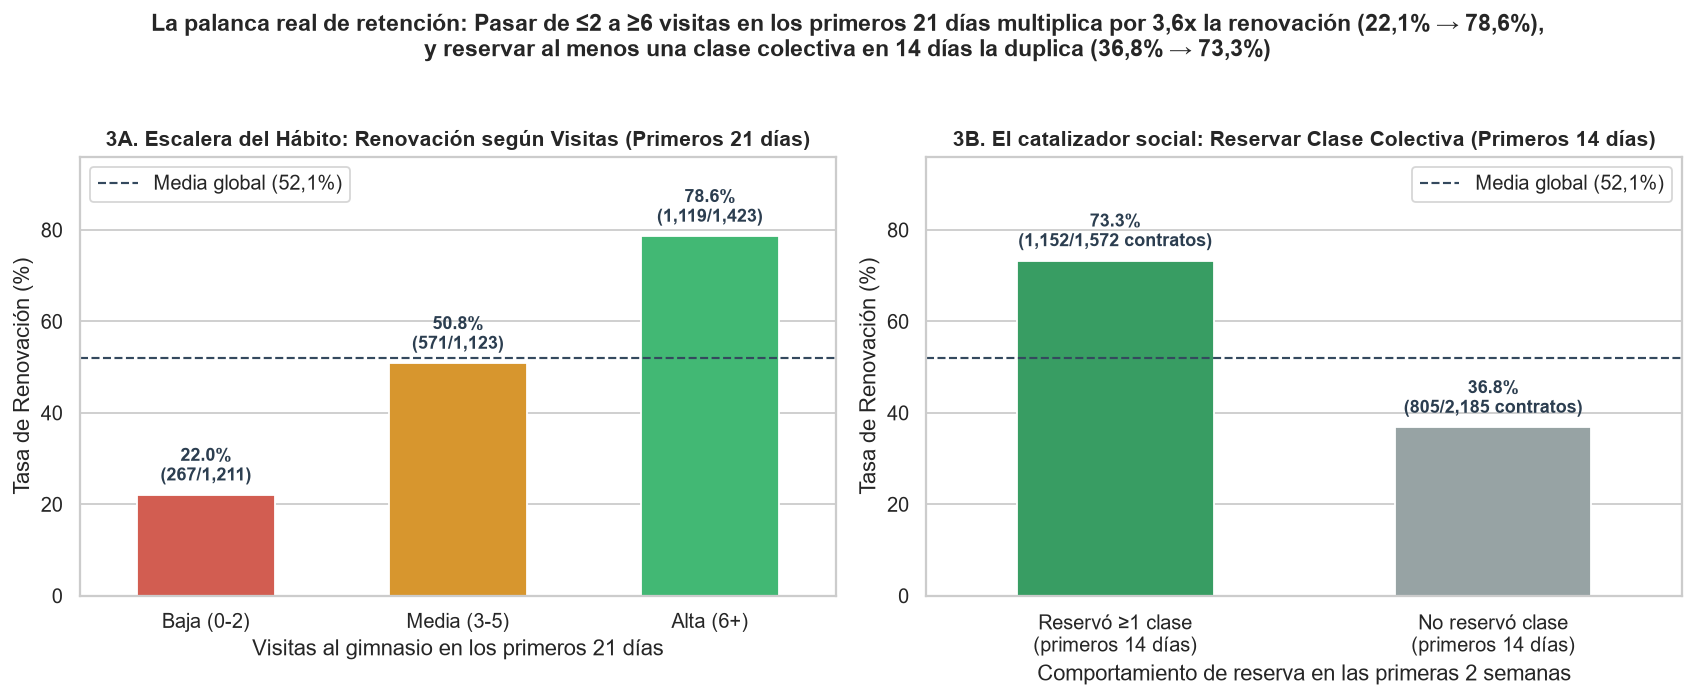

=== CIFRAS DEL GRÁFICO 3: LA ESCALERA DEL HÁBITO (21 DÍAS) Y CLASES COLECTIVAS (14 DÍAS) ===
- Tramo Baja (0-2) : 1,211 contratos | Renovados: 267 | Tasa de renovación: 22.05%
- Tramo Media (3-5): 1,123 contratos | Renovados: 571 | Tasa de renovación: 50.85%
- Tramo Alta (6+)  : 1,423 contratos | Renovados: 1,119 | Tasa de renovación: 78.64%
- Reservó clase (<=14d)   : 1,572 contratos | Renovados: 1,152 | Tasa de renovación: 73.28%
- No reservó clase (<=14d): 2,185 contratos | Renovados: 805 | Tasa de renovación: 36.84%


In [4]:
# --- GRÁFICO 3: La Escalera del Hábito (21 días) y el Catalizador de Clases Colectivas (14 días) ---
df_esc = (
    df_base.groupby("tramo_asistencia", as_index=False)
    .agg(
        total_contratos=("renovo", "count"),
        renovados=("renovo", "sum"),
        tasa_renov=("renovo", lambda x: x.mean() * 100),
    )
)
orden_tramos = ["Baja (0-2)", "Media (3-5)", "Alta (6+)"]
df_esc["tramo_asistencia"] = pd.Categorical(df_esc["tramo_asistencia"], categories=orden_tramos, ordered=True)
df_esc = df_esc.sort_values("tramo_asistencia").reset_index(drop=True)

df_res = (
    df_base.groupby("reservo_clase_14d", as_index=False)
    .agg(
        total_contratos=("renovo", "count"),
        renovados=("renovo", "sum"),
        tasa_renov=("renovo", lambda x: x.mean() * 100),
    )
    .sort_values("reservo_clase_14d", ascending=False)
    .reset_index(drop=True)
)
df_res["etiqueta_reserva"] = df_res["reservo_clase_14d"].map({
    True: "Reservó ≥1 clase\n(primeros 14 días)",
    False: "No reservó clase\n(primeros 14 días)"
})

fig, axes = plt.subplots(1, 2, figsize=(13.2, 5.2))
palette_esc = ["#E74C3C", "#F39C12", "#2ECC71"]

# Panel 3A: Escalera de visitas en 21 días
sns.barplot(
    data=df_esc, x="tramo_asistencia", y="tasa_renov", hue="tramo_asistencia",
    palette=palette_esc, dodge=False, legend=False, width=0.55, ax=axes[0]
)
axes[0].axhline(52.09, color="#34495E", linestyle="--", linewidth=1.2, label="Media global (52,1%)")
axes[0].set_title("3A. Escalera del Hábito: Renovación según Visitas (Primeros 21 días)", fontsize=11.5, fontweight="bold")
axes[0].set_xlabel("Visitas al gimnasio en los primeros 21 días")
axes[0].set_ylabel("Tasa de Renovación (%)")
axes[0].set_ylim(0, 96)
axes[0].legend(loc="upper left", frameon=True)
for i, r in enumerate(df_esc.itertuples()):
    axes[0].text(
        i, r.tasa_renov + 2.0,
        f"{r.tasa_renov + 1e-6:.1f}%\n({int(r.renovados):,}/{int(r.total_contratos):,})",
        ha="center", va="bottom", fontweight="bold", fontsize=10, color="#2C3E50"
    )

# Panel 3B: Efecto de reservar clase colectiva en los primeros 14 días
sns.barplot(
    data=df_res, x="etiqueta_reserva", y="tasa_renov", hue="etiqueta_reserva",
    palette=["#27AE60", "#95A5A6"], dodge=False, legend=False, width=0.52, ax=axes[1]
)
axes[1].axhline(52.09, color="#34495E", linestyle="--", linewidth=1.2, label="Media global (52,1%)")
axes[1].set_title("3B. El catalizador social: Reservar Clase Colectiva (Primeros 14 días)", fontsize=11.5, fontweight="bold")
axes[1].set_xlabel("Comportamiento de reserva en las primeras 2 semanas")
axes[1].set_ylabel("Tasa de Renovación (%)")
axes[1].set_ylim(0, 96)
axes[1].legend(loc="upper right", frameon=True)
for i, r in enumerate(df_res.itertuples()):
    axes[1].text(
        i, r.tasa_renov + 2.0,
        f"{r.tasa_renov + 1e-6:.1f}%\n({int(r.renovados):,}/{int(r.total_contratos):,} contratos)",
        ha="center", va="bottom", fontweight="bold", fontsize=10, color="#2C3E50"
    )

plt.suptitle(
    "La palanca real de retención: Pasar de ≤2 a ≥6 visitas en los primeros 21 días multiplica por 3,6x la renovación (22,1% → 78,6%),\ny reservar al menos una clase colectiva en 14 días la duplica (36,8% → 73,3%)",
    fontsize=12.5, fontweight="bold", y=1.03
)
plt.tight_layout()
out_g3 = REPORTS_DIR / "03_escalera_habito_21_dias.png"
plt.savefig(out_g3, dpi=300, bbox_inches="tight")
# Mantener también la ruta histórica en reports/figures/
plt.savefig(FIGURES_DIR / "fig1_escalera_habito.png", dpi=300, bbox_inches="tight")
plt.show()

print("=== CIFRAS DEL GRÁFICO 3: LA ESCALERA DEL HÁBITO (21 DÍAS) Y CLASES COLECTIVAS (14 DÍAS) ===")
for r in df_esc.itertuples():
    print(f"- Tramo {r.tramo_asistencia:11s}: {r.total_contratos:,} contratos | Renovados: {int(r.renovados):,} | Tasa de renovación: {r.tasa_renov:.2f}%")
for r in df_res.itertuples():
    lbl = "Reservó clase (<=14d)" if r.reservo_clase_14d else "No reservó clase (<=14d)"
    print(f"- {lbl:24s}: {r.total_contratos:,} contratos | Renovados: {int(r.renovados):,} | Tasa de renovación: {r.tasa_renov:.2f}%")


### Análisis del Gráfico 3 y Presentación del Gráfico 4 (`04_control_confusion_habito_vs_plan.png`)
* **Lectura del Gráfico 3:** La retención se decide en las tres primeras semanas: quien supera las **6 visitas en 21 días renueva al $78,6\%$**, frente al **$50,9\%$** de quienes asisten `3–5` veces y apenas el **$22,1\%$** de quienes asisten `0–2` veces. Reservar una clase dirigida en los primeros 14 días impulsa la renovación del **$36,8\%$ al $73,3\%$**.
* **El Blindaje contra la Paradoja de Simpson (Gráfico 4):** Para demostrar ante el Comité que el tipo de contrato no causa por sí mismo la fidelidad ni la deserción, cruzamos **Hábito Temprano $\times$ Tipo de Plan**. En el panel izquierdo probamos que **dentro de cada tramo de asistencia, anual y mensual renuevan exactamente igual** ($78,2\%$ vs $78,8\%$ en alta asistencia); en el panel derecho mostramos por qué el anual pierde en el agregado: **el $51,6\%$ de los socios anuales cae en el tramo de baja asistencia inicial (`0–2` visitas)** frente a solo el **$18,9\%$** de los mensuales.

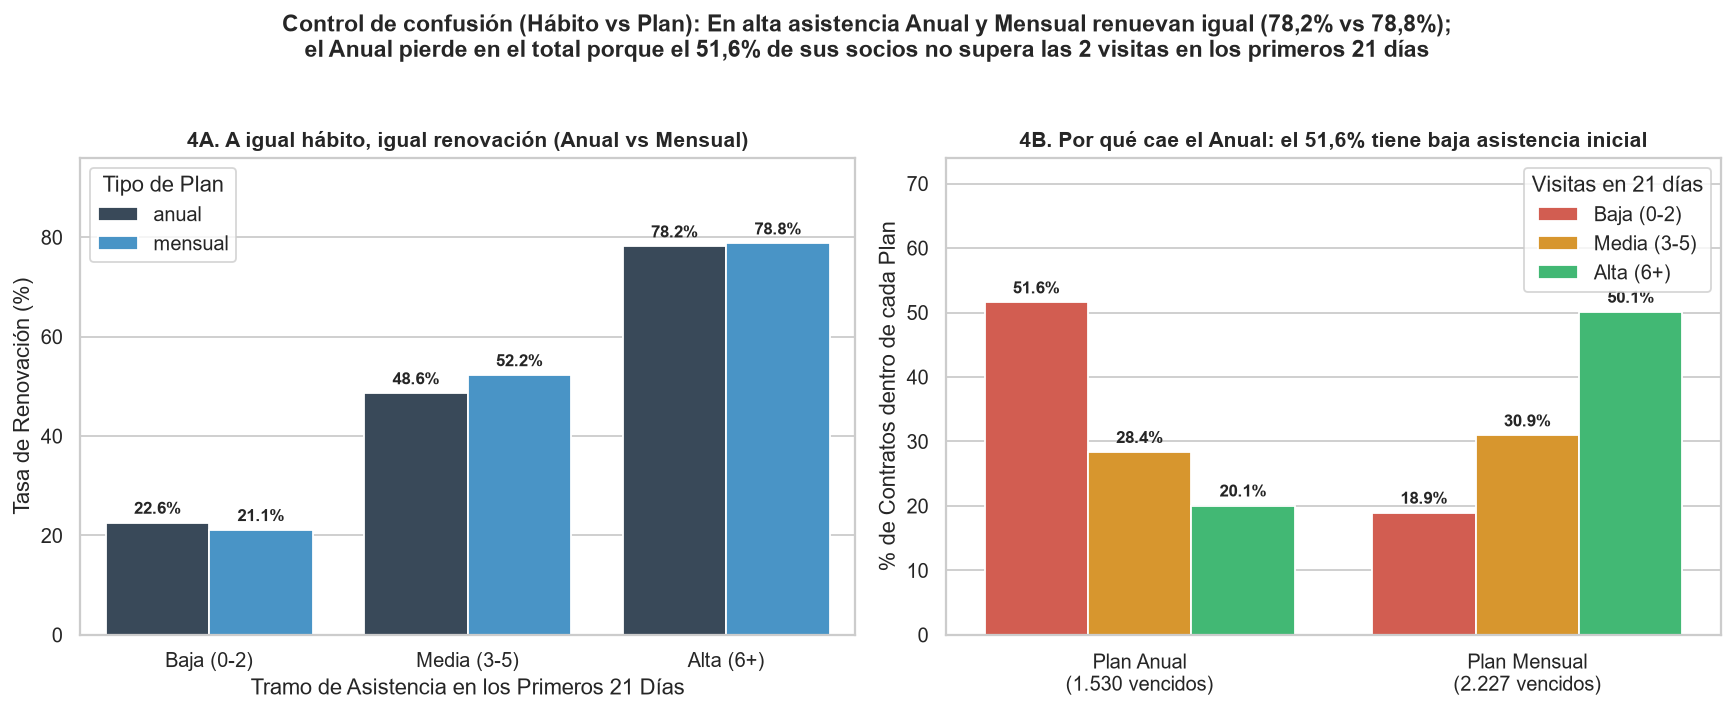

=== CIFRAS DEL GRÁFICO 4: CONTROL DE CONFUSIÓN (TRAMO DE ASISTENCIA 21D x PLAN) ===
- Baja (0-2)  | anual  :  789 contratos ( 51.6% del plan) | Renovados:  178 | Renovación: 22.56%
- Baja (0-2)  | mensual:  422 contratos ( 18.9% del plan) | Renovados:   89 | Renovación: 21.09%
- Media (3-5) | anual  :  434 contratos ( 28.4% del plan) | Renovados:  211 | Renovación: 48.62%
- Media (3-5) | mensual:  689 contratos ( 30.9% del plan) | Renovados:  360 | Renovación: 52.25%
- Alta (6+)   | anual  :  307 contratos ( 20.1% del plan) | Renovados:  240 | Renovación: 78.18%
- Alta (6+)   | mensual: 1116 contratos ( 50.1% del plan) | Renovados:  879 | Renovación: 78.76%

Los 4 gráficos ejecutivos se han guardado correctamente en 'reports/'.


In [5]:
# --- GRÁFICO 4: Control de confusión Hábito vs Plan y Distribución de Asistencia por Plan ---
df_ctrl = (
    df_base.groupby(["tramo_asistencia", "tipo_plan"], as_index=False)
    .agg(
        contratos=("renovo", "count"),
        renovados=("renovo", "sum"),
        tasa_renov=("renovo", lambda x: x.mean() * 100 + 1e-6),
    )
)
df_ctrl["tramo_asistencia"] = pd.Categorical(df_ctrl["tramo_asistencia"], categories=orden_tramos, ordered=True)
df_ctrl = df_ctrl.sort_values(["tramo_asistencia", "tipo_plan"]).reset_index(drop=True)
df_ctrl["pct_en_plan"] = df_ctrl.groupby("tipo_plan")["contratos"].transform(lambda s: s / s.sum() * 100)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.3))
palette_plans = {"anual": "#34495E", "mensual": "#3498DB"}

# Panel 4A: Renovación por tramo de asistencia y plan (Anual vs Mensual)
sns.barplot(
    data=df_ctrl, x="tramo_asistencia", y="tasa_renov", hue="tipo_plan",
    order=orden_tramos, palette=palette_plans, ax=axes[0]
)
axes[0].set_title("4A. A igual hábito, igual renovación (Anual vs Mensual)", fontsize=11.5, fontweight="bold")
axes[0].set_xlabel("Tramo de Asistencia en los Primeros 21 Días")
axes[0].set_ylabel("Tasa de Renovación (%)")
axes[0].set_ylim(0, 96)
axes[0].legend(title="Tipo de Plan", frameon=True, loc="upper left")
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.1f%%", padding=3, fontweight="bold", fontsize=9.5)

# Panel 4B: Distribución de los contratos de cada plan según su tramo de asistencia inicial
df_dist_plot = df_ctrl.copy()
df_dist_plot["etiqueta_plan"] = df_dist_plot["tipo_plan"].map({"anual": "Plan Anual\n(1.530 vencidos)", "mensual": "Plan Mensual\n(2.227 vencidos)"})
sns.barplot(
    data=df_dist_plot, x="etiqueta_plan", y="pct_en_plan", hue="tramo_asistencia",
    palette=palette_esc, ax=axes[1]
)
axes[1].set_title("4B. Por qué cae el Anual: el 51,6% tiene baja asistencia inicial", fontsize=11.5, fontweight="bold")
axes[1].set_xlabel("")
axes[1].set_ylabel("% de Contratos dentro de cada Plan")
axes[1].set_ylim(0, 74)
axes[1].legend(title="Visitas en 21 días", frameon=True, loc="upper right")
for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.1f%%", padding=3, fontweight="bold", fontsize=9.5)

plt.suptitle(
    "Control de confusión (Hábito vs Plan): En alta asistencia Anual y Mensual renuevan igual (78,2% vs 78,8%);\nel Anual pierde en el total porque el 51,6% de sus socios no supera las 2 visitas en los primeros 21 días",
    fontsize=12.5, fontweight="bold", y=1.03
)
plt.tight_layout()
out_g4 = REPORTS_DIR / "04_control_confusion_habito_vs_plan.png"
plt.savefig(out_g4, dpi=300, bbox_inches="tight")
# Mantener también las figuras individuales de reports/figures/
plt.savefig(FIGURES_DIR / "fig2_control_robustez.png", dpi=300, bbox_inches="tight")
plt.savefig(FIGURES_DIR / "fig3_distribucion_sesgo.png", dpi=300, bbox_inches="tight")
plt.show()

print("=== CIFRAS DEL GRÁFICO 4: CONTROL DE CONFUSIÓN (TRAMO DE ASISTENCIA 21D x PLAN) ===")
for r in df_ctrl.itertuples():
    print(f"- {r.tramo_asistencia:11s} | {r.tipo_plan:7s}: {r.contratos:4d} contratos ({r.pct_en_plan:5.1f}% del plan) | Renovados: {int(r.renovados):4d} | Renovación: {r.tasa_renov:.2f}%")
print("\nLos 4 gráficos ejecutivos se han guardado correctamente en 'reports/'.")


### Conclusión Final y Recomendación Accionable para el Comité de Dirección

Con el espejismo del prepago desmontado y el efecto causal del hábito temprano blindado frente al tipo de plan, la edad, el canal y la sede, nuestra recomendación para **Marta Belmonte (CEO)** se concreta en **tres decisiones inmediatas**:

1. **Cancelar la ampliación presupuestaria de la campaña «Pásate al Anual»:**
   * Empujar con descuentos el paso a cuota anual no compra fidelidad: solo infla la caja del mes 1 mientras llena los clubes de un **$51,6\%$ de socios sin hábito inicial** y un **$35,5\%$ de inactivos crónicos (`980` socios)** que se dan de baja masivamente al vencer el año ($41,1\%$ de renovación).
2. **Redirigir el presupuesto al Programa de Onboarding Conductual «6 Visitas en 21 Días + 1ª Clase Colectiva»:**
   * **Día 1 (Alta):** Reserva asistida obligatoria de la **primera clase colectiva dentro de los primeros 14 días** (duplica la renovación del **$36,8\%$ al $73,3\%$**).
   * **Días 1 a 21:** Alerta automática en app y recepción cuando un socio nuevo acumule **$> 5$ días sin check-in**, con contacto activo del monitor para llevarlo al umbral de **$\ge 6$ visitas en 21 días** (**$78,6\%$ de renovación**, tanto en anual [$78,2\%$] como en mensual [$78,8\%$]).
   * **Impacto potencial:** Si el plan anual redujese su bolsa de baja asistencia inicial del $51,6\%$ al $18,9\%$ que hoy tiene el plan mensual, su tasa de renovación subiría del **$41,1\%$ al $58,6\%$ (`+268` renovaciones anuales adicionales por cohorte, equivalentes a $\sim +120.000\text{ €}$ anuales retenidos sin gastar un euro extra en captación)**.
3. **Cambiar los KPIs del Cuadro de Mando de Dirección:**
   * Sustituir el *LTV inicial cobrado* y los *Socios con cuota activa* por tres indicadores operativos: **1) % de Nuevas Altas con $\ge 6$ visitas en 21 días**, **2) % de Nuevas Altas con reserva de clase en 14 días**, y **3) Socios Activos con Asistencia Efectiva ($\le 28$ días)** junto a la **Tasa de Renovación por Cohorte al Vencimiento**.

#### Entregables generados en `reports/`:
* [`ONE_PAGER.md`](reports/ONE_PAGER.md)
* [`01_ltv_inicial_vs_tasa_renovacion.png`](reports/01_ltv_inicial_vs_tasa_renovacion.png)
* [`02_cementerio_inactivos_sesgo_supervivencia.png`](reports/02_cementerio_inactivos_sesgo_supervivencia.png)
* [`03_escalera_habito_21_dias.png`](reports/03_escalera_habito_21_dias.png)
* [`04_control_confusion_habito_vs_plan.png`](reports/04_control_confusion_habito_vs_plan.png)